In [19]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [5]:
df = pd.read_csv('C:/Users/HP/OneDrive/Desktop/KPMG sem3/DECSSION_tree_SVM_RandomForest/HR-Attrition-ML-V1.csv')

In [6]:
df.head()

,Employee_ID,Age,Gender,Department,Job_Role,Education_Level,Marital_Status,Years_Experience,Years_At_Company,Years_In_Current_Role,...,Business_Travel,Distance_From_Home_KM,Num_Companies_Worked,Salary_Hike_Percent,Stock_Option_Level,Projects_Handled,Absences_Last_Year,Remote_Work,Manager_Support,Attrition
0,EMP00001,24,Male,Human Resources,Sales Manager,Bachelor,Married,3,0,0,...,Travel_Rarely,27,5,18,2,1,11,No,4,Yes
1,EMP00002,51,Male,IT,IT Analyst,Bachelor,Married,23,9,8,...,Non-Travel,25,5,24,1,1,10,No,3,Yes
2,EMP00003,47,Male,Sales,Sales Manager,Doctorate,Single,27,14,8,...,Travel_Rarely,27,5,16,3,5,1,No,1,No
3,EMP00004,38,Male,Research & Development,Research Scientist,High School,Single,16,12,2,...,Travel_Rarely,11,7,18,2,5,11,Yes,4,No
4,EMP00005,38,Male,Human Resources,HR Specialist,High School,Single,13,4,4,...,Travel_Rarely,5,6,25,3,5,13,No,3,Yes


In [7]:
df.columns

Index(['Employee_ID', 'Age', 'Gender', 'Department', 'Job_Role',
       'Education_Level', 'Marital_Status', 'Years_Experience',
       'Years_At_Company', 'Years_In_Current_Role',
       'Years_Since_Last_Promotion', 'Monthly_Income', 'Overtime',
       'Job_Satisfaction', 'Work_Life_Balance', 'Environment_Satisfaction',
       'Job_Involvement', 'Performance_Rating', 'Training_Hours_Last_Year',
       'Business_Travel', 'Distance_From_Home_KM', 'Num_Companies_Worked',
       'Salary_Hike_Percent', 'Stock_Option_Level', 'Projects_Handled',
       'Absences_Last_Year', 'Remote_Work', 'Manager_Support', 'Attrition'],
      dtype='object')

In [8]:
df.isnull().sum()

Employee_ID                   0
Age                           0
Gender                        0
Department                    0
Job_Role                      0
Education_Level               0
Marital_Status                0
Years_Experience              0
Years_At_Company              0
Years_In_Current_Role         0
Years_Since_Last_Promotion    0
Monthly_Income                0
Overtime                      0
Job_Satisfaction              0
Work_Life_Balance             0
Environment_Satisfaction      0
Job_Involvement               0
Performance_Rating            0
Training_Hours_Last_Year      0
Business_Travel               0
Distance_From_Home_KM         0
Num_Companies_Worked          0
Salary_Hike_Percent           0
Stock_Option_Level            0
Projects_Handled              0
Absences_Last_Year            0
Remote_Work                   0
Manager_Support               0
Attrition                     0
dtype: int64

In [23]:
X = df.drop(['Attrition'] , axis =1)
Y = df['Attrition']

print(X.shape)
print(Y.shape)

(15000, 28)
(15000,)


In [24]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [25]:
# Prepare categorical and numerical data

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=['number']
).columns.tolist()

# Convert categories into numeric indicator columns
encoder = OneHotEncoder(handle_unknown="ignore")

# Prepare data for Decision Tree and Random Forest
preprocessor_tree = ColumnTransformer(
    [
        ('cat', encoder, categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

# Prepare data for SVM, including scaling numerical variables
preprocessor_svm = ColumnTransformer(
    [
        ('cat', OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

print('Categorical columns:', len(categorical_cols))
print('Numerical columns:', len(numerical_cols))

Categorical columns: 9
Numerical columns: 19


# Decission tree

In [35]:
dt_model = Pipeline(
    [
        ('preprocessor', preprocessor_tree),
        ('model', DecisionTreeClassifier(max_depth= 12, min_samples_leaf=5, class_weight='balanced', random_state=42))
    ]) 


dt_model.fit(x_train, y_train)
dt_predictions = dt_model.predict(x_test)
print('Decision Tree Classifier:')
print('Accuracy:', round(accuracy_score(y_test, dt_predictions), 4))

print('Classification Report:')
print(classification_report(y_test, dt_predictions))



Decision Tree Classifier:
Accuracy: 0.5903
Classification Report:
              precision    recall  f1-score   support

          No       0.68      0.64      0.66      1860
         Yes       0.46      0.51      0.49      1140

    accuracy                           0.59      3000
   macro avg       0.57      0.57      0.57      3000
weighted avg       0.60      0.59      0.59      3000



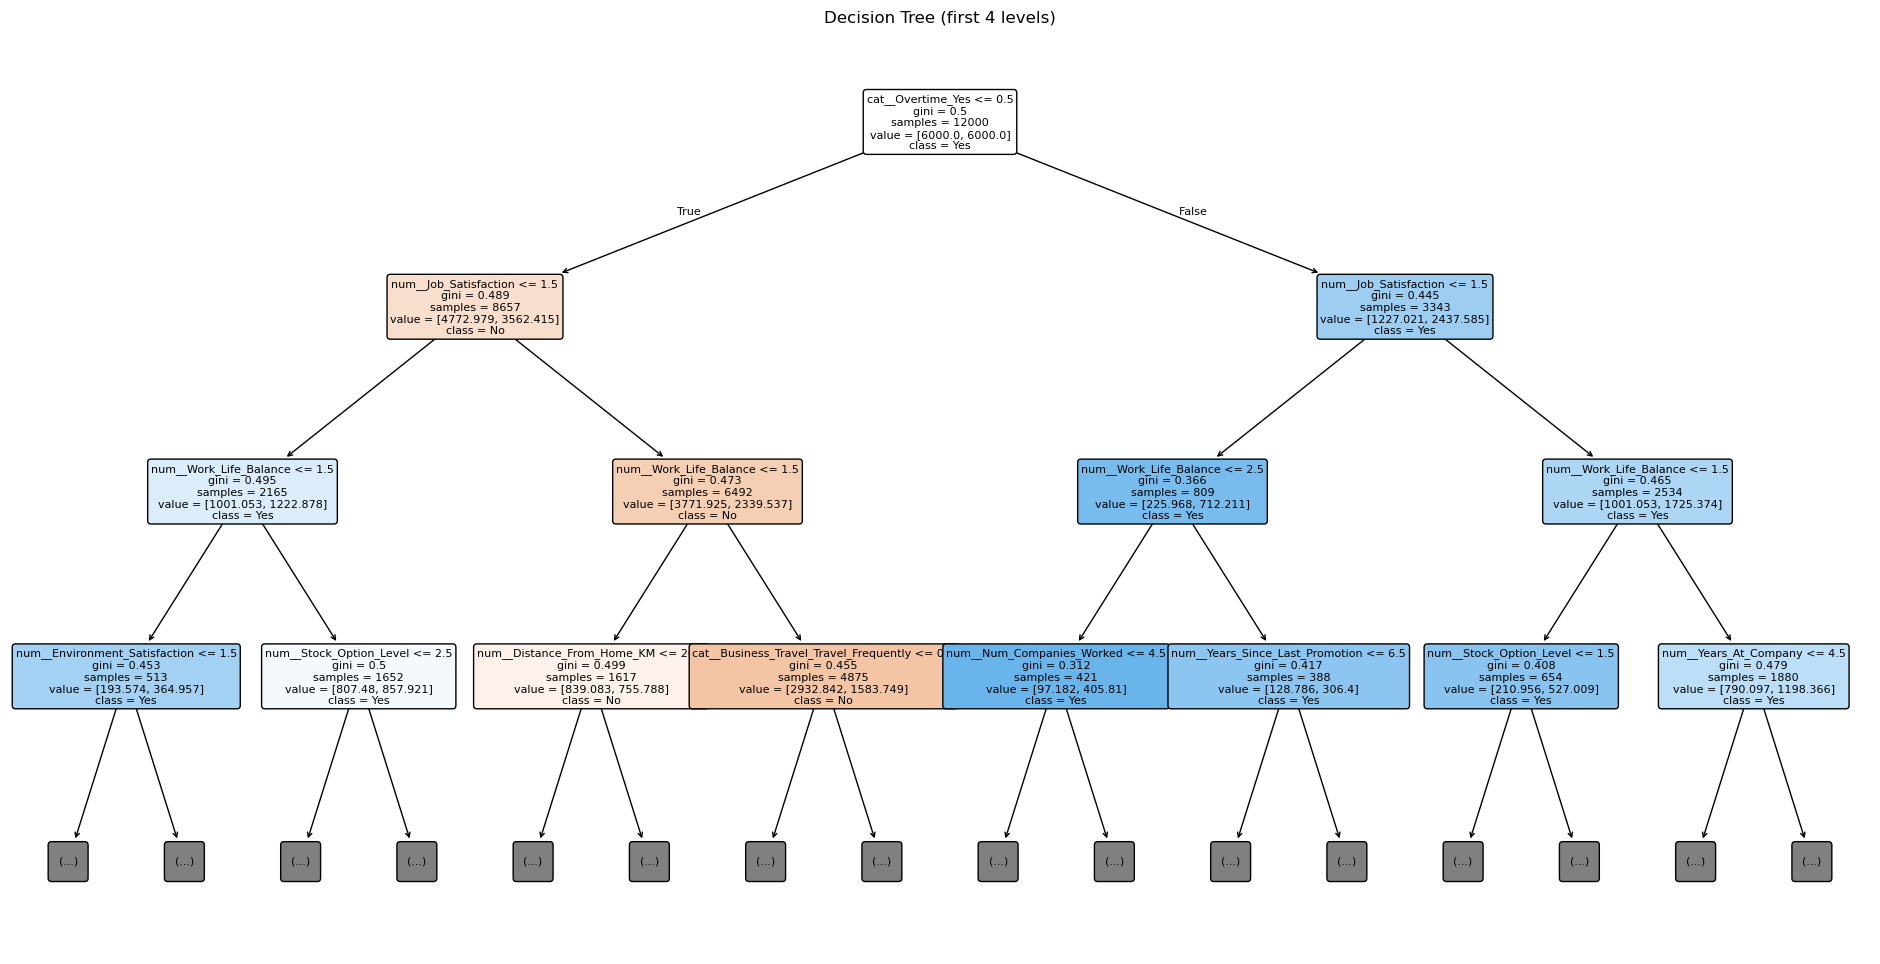

In [39]:
from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

feature_names = dt_model.named_steps["preprocessor"].get_feature_names_out()
tree = dt_model.named_steps["model"]

plt.figure(figsize=(24, 12))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (first 4 levels)")
plt.show()

# Random forest


In [41]:
rf_model = Pipeline([
   
        ('preprocessor', preprocessor_tree),
        ('model', RandomForestClassifier(
            n_estimators=100,
             max_depth=12,
              min_samples_leaf=5, 
              class_weight='balanced', 
              random_state=42
        ))


])

rf_model.fit(x_train, y_train)
rf_predictions = rf_model.predict(x_test)
print('rf_model prediction ', rf_predictions)

print("Random forest Accuracy:", round(accuracy_score(y_test, rf_predictions), 4))

print('Classification Report:', classification_report(y_test, rf_predictions))


rf_model prediction  ['No' 'No' 'No' ... 'Yes' 'No' 'No']
Random forest Accuracy: 0.6427
Classification Report:               precision    recall  f1-score   support

          No       0.73      0.68      0.70      1860
         Yes       0.53      0.58      0.55      1140

    accuracy                           0.64      3000
   macro avg       0.63      0.63      0.63      3000
weighted avg       0.65      0.64      0.65      3000



# SVM


In [44]:
svm_model = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC( kernel="rbf", C=0.1, class_weight='balanced'))
])

svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions), 4))
print("Classification Report:")
print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.652
Classification Report:
              precision    recall  f1-score   support

          No       0.74      0.68      0.71      1860
         Yes       0.54      0.60      0.57      1140

    accuracy                           0.65      3000
   macro avg       0.64      0.64      0.64      3000
weighted avg       0.66      0.65      0.66      3000



In [46]:
svm_model = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC(kernel='poly', degree=3, C=0.1, class_weight='balanced'))
    ])

svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions),4))
print("Classification Report:")
print(classification_report(y_test, svm_predictions))



SVM Accuracy: 0.648
Classification Report:
              precision    recall  f1-score   support

          No       0.74      0.67      0.70      1860
         Yes       0.53      0.61      0.57      1140

    accuracy                           0.65      3000
   macro avg       0.63      0.64      0.64      3000
weighted avg       0.66      0.65      0.65      3000



In [49]:
svm_model = Pipeline([
    ('preprocessor', preprocessor_svm),
    ('model', SVC(kernel='sigmoid', degree=3, C=0.1, class_weight='balanced'))
    ])

svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:", round(accuracy_score(y_test, svm_predictions),4))
print("Classification Report:")
print(classification_report(y_test, svm_predictions))



SVM Accuracy: 0.6477
Classification Report:
              precision    recall  f1-score   support

          No       0.73      0.69      0.71      1860
         Yes       0.53      0.57      0.55      1140

    accuracy                           0.65      3000
   macro avg       0.63      0.63      0.63      3000
weighted avg       0.65      0.65      0.65      3000

